# 15 · Add whole TV series to the best movie recommender

Use the best model by validation Recall@10 so far: **CF + plots + cast + IMDb**, with binary likes at **8/10 or higher**. The 7+ threshold and dislike-penalty experiments did not improve its primary recall metric.

This notebook adds **whole TV series and mini-series** as recommendation candidates and rating-profile items. New series use TV summaries, exact IMDb cast identities, and IMDb audience ratings. A rated series can contribute plot and cast preferences to recommendations for both movies and TV.

**The data limit matters:** the MovieLens files contain a few series/miniseries, but most new series have no individual held-out ratings from these users. We can verify that inference works and measure the small observed subset; adding metadata alone cannot establish broad TV accuracy.

The existing app and earlier notebooks retain their current model. No LLM or paid API is used.


In [1]:
from pathlib import Path
import os
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "scripts").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "scripts/tv_series_experiment.py").is_file(), "Run from the project or notebooks folder."
sys.path.insert(0, str(ROOT))
(ROOT / "data/.matplotlib").mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "data/.matplotlib"))

import json
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from threadpoolctl import threadpool_limits
from scripts.prepare_tv_series import prepare_catalog
from scripts.tv_series_experiment import build_extended_model, run_experiment, recommend_profile
from scripts.export_web_model import file_hash
pd.set_option("display.max_columns", 18)
pd.set_option("display.max_colwidth", 65)


## Sources, identities and experimental boundaries

- Fetch only [TVmaze show-index page zero](https://www.tvmaze.com/api): at most 250 stable show IDs. Prespecified selection is English-language Scripted, Animation and Documentary shows with exact IMDb IDs. This is a bounded convenience catalog, not a representative sample of all television.
- Verify whole-series/mini-series types using the official IMDb `title.basics` data. Classify **all MovieLens-linked titles** too, so episode entries are not confused with series.
- Get cast from IMDb `title.principals` using exact `tt…` title IDs and `nm…` person IDs. Keep the same first-five-distinct actor/actress policy as the existing model. TVmaze person IDs and actor names are not used as IMDb identity keys.
- Get audience averages and vote counts from IMDb `title.ratings`. They are aggregate title ratings, **not** individual collaborative user histories. TVmaze audience scores are not substituted.
- Cache these subsets under a separate directory and record source URLs, retrieval times and SHA-256 hashes. Earlier caches are preserved. The first run streams roughly a gigabyte of compressed IMDb metadata; subsequent runs reuse verified subsets.
- Whole series use their existing `ml:movieId` identity when exactly linked to MovieLens, otherwise `imdb:tt…`. A series already in the original candidate catalog is not duplicated. Episodes and specials are never promoted to parent-series ratings.

TV summaries and metadata are attributed to [TVmaze](https://www.tvmaze.com/) under its [CC BY-SA API terms](https://www.tvmaze.com/api#licensing). IMDb's [non-commercial dataset terms](https://data.imdb.com/non-commercial-datasets/) apply to the IMDb data.

The canonical chronological train/validation split is unchanged. We never parse test feedback, merge unrelated user IDs, or invent user ratings for the new series.


In [2]:
catalog_path = prepare_catalog(ROOT)
print("Verified TV catalog:", catalog_path)
with threadpool_limits(limits=2):
    model = build_extended_model(ROOT)
items = pd.DataFrame(model["items"])
display(pd.DataFrame([{
    "original candidates": int(model["reference"].sum()),
    "expanded candidates": len(items),
    "added whole series": int(items["added"].sum()),
    "whole series already in original catalog": int((items["isSeries"] & ~items["added"]).sum()),
    "like threshold / 10": 8,
}]))
display(items.loc[items["added"], ["itemId", "title", "year", "titleType", "tvmazeUrl"]].head(15).reset_index(drop=True))


Using verified TVmaze page zero.
Using verified TV subset: title.basics
Using verified TV subset: title.principals
Using verified TV subset: title.ratings
Prepared 223 TV series; classified 9742 MovieLens entries.
Catalog: C:\Users\clark\OneDrive\Documents\Projects\movie-recommendation-system\data\raw\notebook15_tv_series\catalog.json
Verified TV catalog: C:\Users\clark\OneDrive\Documents\Projects\movie-recommendation-system\data\raw\notebook15_tv_series\catalog.json


,original candidates,expanded candidates,added whole series,whole series already in original catalog,like threshold / 10
0,6885,7108,223,46,8


,itemId,title,year,titleType,tvmazeUrl
0,imdb:tt0096697,The Simpsons,1989.0,tvSeries,https://www.tvmaze.com/shows/83/the-simpsons
1,imdb:tt0098936,Twin Peaks,1990.0,tvSeries,https://www.tvmaze.com/shows/156/twin-peaks
2,imdb:tt0118375,King of the Hill,1997.0,tvSeries,https://www.tvmaze.com/shows/115/king-of-the-hill
3,imdb:tt0118480,Stargate SG·1,1997.0,tvSeries,https://www.tvmaze.com/shows/204/stargate-sg1
4,imdb:tt0121955,South Park,1997.0,tvSeries,https://www.tvmaze.com/shows/112/south-park
5,imdb:tt0182576,Family Guy,1999.0,tvSeries,https://www.tvmaze.com/shows/84/family-guy
6,imdb:tt0203259,Law & Order: Special Victims Unit,1999.0,tvSeries,https://www.tvmaze.com/shows/103/law-order-special-victims-unit
7,imdb:tt0247082,CSI: Crime Scene Investigation,2000.0,tvSeries,https://www.tvmaze.com/shows/109/csi-crime-scene-investigation
8,imdb:tt0285331,24,2001.0,tvSeries,https://www.tvmaze.com/shows/167/24
9,imdb:tt0303461,Firefly,2002.0,tvSeries,https://www.tvmaze.com/shows/180/firefly


## Extend features without changing the original model

| Component | Original movies/series | Newly added series |
|---|---|---|
| Collaborative item basis | Original training likes | **Zero**: no shared user-rating history |
| Plot features | Original training-only TF-IDF | Transform TV summaries through the same frozen vocabulary and IDF |
| Cast features | Original training-only IMDb-person vocabulary/IDF | Transform exact cast IDs; unknown people contribute zero |
| IMDb adjustment | Original aggregate snapshot | New official aggregates, smoothed using the original movie prior center and vote strength |
| Blend weights | Original selected values | Same values |

Every normalization step uses the **original unseen candidate catalog** as its reference. This keeps original candidate scores unchanged when TV candidates are appended. A new-series affinity can exceed the old catalog's maximum; it is not clipped.

Missing plot/cast features remain zero, and the original missing-profile fallbacks still apply. A new TV rating contributes to plot/cast preferences but cannot create collaborative training history. With no usable liked profile, results use only the frozen IMDb adjustment, as in the notebook benchmark.

Cross-domain score calibration has not been tuned. Showing a separate TV list helps inspect content transfer without claiming that mixed-list movie and series scores are already calibrated for live use.


In [3]:
coverage = model["coverage"]
display(coverage.groupby(["added", "isSeries"], dropna=False).agg(
    titles=("itemId", "size"),
    with_collaborative_features=("has_cf", "sum"),
    with_plot_features=("has_plots", "sum"),
    with_known_cast=("has_cast", "sum"),
).reset_index())
print("Frozen blend weights:", model["context"]["metadata"]["weights"])
print("Frozen IMDb prior center:", model["context"]["metadata"]["imdbPriorCenter"])
print("New series have observed collaborative history:", bool(coverage.loc[coverage["added"], "has_cf"].any()))


Frozen blend weights: {'plot': 0.25, 'credits': 0.25, 'imdb': 0.1}
Frozen IMDb prior center: 6.701324021533536
New series have observed collaborative history: False


,added,isSeries,titles,with_collaborative_features,with_plot_features,with_known_cast
0,False,False,6839,4353,5048,6339
1,False,True,46,36,9,36
2,True,True,223,0,223,188


In [4]:
result = run_experiment(model=model)
assert result["manifest"]["control_parity"]["verified"]
assert result["manifest"]["original_score_parity"]["verified"]
assert result["manifest"]["test_feedback_read"] is False
assert result["manifest"]["app_model_changed"] is False
display(result["title_coverage"])
print("Original benchmark reproduced for", result["manifest"]["control_parity"]["users"], "validation users.")
print("Original scores preserved for", result["manifest"]["original_score_parity"]["users"], "training users.")
print("Saved artifacts:", result["output"])


Original benchmark reproduced for 594 validation users.
Original scores preserved for 610 training users.
Saved artifacts: C:\Users\clark\OneDrive\Documents\Projects\movie-recommendation-system\data\processed\per_user_chronological_60_20_20_v1\notebook15_tv_series


,titleType,catalog_titles,training_events,training_likes,validation_events,validation_likes
0,movie,9068,59637,29513,19850,9032
1,short,104,178,120,56,37
2,tvEpisode,33,38,25,18,14
3,tvMiniSeries,80,80,54,45,26
4,tvMovie,167,95,52,73,27
5,tvSeries,7,3,3,3,1
6,tvShort,11,3,2,2,0
7,tvSpecial,79,24,10,36,29
8,unknown,23,37,18,21,14
9,video,170,160,65,60,29


## What can be measured

1. **Original benchmark:** reproduce the saved per-user results on the original candidate catalog. The control already contains the few TV titles that MovieLens included.
2. **Expanded mixed catalog:** evaluate the same known validation positives and users after adding TV candidates. This measures competition under existing sparse labels. New series without labels cannot earn measured hits, so this is **not a clean estimate of overall TV recommendation quality**.
3. **Tiny observed TV subset:** use only exact-ID-verified whole-series/mini-series validation labels. Report users and positive counts explicitly; retain unavailable series in metric denominators. The original and expanded series shortlists have different candidate availability.
4. **Observed TV-profile ablation:** for users with training series likes and held-out movie likes, compare including versus ignoring those series likes in their profiles. Keep CF training features and all-rated exclusions fixed. This isolates profile use on a small existing cohort, not retraining the whole model.

All outcomes are exploratory validation results. Most new series need actual individual ratings before their recommendation quality can be evaluated.


In [5]:
summary = result["summary"]
display(summary)
tv_coverage = result["title_coverage"].loc[
    result["title_coverage"]["titleType"].isin(["tvSeries", "tvMiniSeries"])
]
display(Markdown(
    f"MovieLens contains **{int(tv_coverage['catalog_titles'].sum())} verified whole-series/mini-series titles**, "
    f"with **{int(tv_coverage['training_likes'].sum())} training likes** and "
    f"only **{int(tv_coverage['validation_likes'].sum())} validation likes** at 8+/10. "
    "The TV-specific metrics below are based on this small observed subset."
))
control = summary.loc[summary["variant"] == "original catalog control"].iloc[0]
expanded = summary.loc[summary["variant"] == "expanded mixed catalog"].iloc[0]
display(Markdown(
    f"Original-label Recall@10: control **{control['mean_recall_at_10']:.6f}**, "
    f"expanded mixed catalog **{expanded['mean_recall_at_10']:.6f}**. "
    "This is a catalog-expansion diagnostic under existing labels, not a measured accuracy score for all added TV series."
))
display(summary.loc[summary["task"] == "TV profile ablation; movie labels only"].reset_index(drop=True))


,variant,task,users,heldout_positive_events,hits_at_10,mean_recall_at_10,mean_ndcg_at_10
0,original catalog control,original validation labels,594,9209,631,0.122573,0.143483
1,expanded mixed catalog,original validation labels,594,9209,631,0.122573,0.143483
2,original series shortlist,tiny observed whole-series validation,17,27,12,0.480392,0.304427
3,expanded series shortlist,tiny observed whole-series validation,17,27,12,0.480392,0.304427
4,include observed series likes,TV profile ablation; movie labels only,34,1071,50,0.071810,0.177661
5,ignore observed series likes,TV profile ablation; movie labels only,34,1071,50,0.071810,0.181572


MovieLens contains **87 verified whole-series/mini-series titles**, with **57 training likes** and only **27 validation likes** at 8+/10. The TV-specific metrics below are based on this small observed subset.

Original-label Recall@10: control **0.122573**, expanded mixed catalog **0.122573**. This is a catalog-expansion diagnostic under existing labels, not a measured accuracy score for all added TV series.

,variant,task,users,heldout_positive_events,hits_at_10,mean_recall_at_10,mean_ndcg_at_10
0,include observed series likes,TV profile ablation; movie labels only,34,1071,50,0.07181,0.177661
1,ignore observed series likes,TV profile ablation; movie labels only,34,1071,50,0.07181,0.181572


In [6]:
stored_recommendations = pd.read_csv(result["output"] / "recommendations.csv")
placements = stored_recommendations.merge(items[["itemId", "added", "isSeries"]], on="itemId", validate="many_to_one")
placement_rows = []
for variant, frame in placements.groupby("variant", sort=False):
    added_picks = frame.loc[frame["added"]]
    placement_rows.append({
        "list": variant, "recommendation slots": len(frame),
        "all series slots": int(frame["isSeries"].sum()),
        "new series slots": len(added_picks),
        "users receiving new series": added_picks["userId"].nunique(),
        "distinct new series": added_picks["itemId"].nunique(),
    })
placement_table = pd.DataFrame(placement_rows)
display(placement_table)
training_like_users = set(model["context"]["train"].loc[model["context"]["train"]["rating"] >= 4, "userId"])
new_mixed = placements.loc[(placements["variant"] == "expanded mixed") & placements["added"]]
personalized_users = new_mixed.loc[new_mixed["userId"].isin(training_like_users), "userId"].nunique()
display(Markdown(
    f"**Mixed-ranking limitation:** added series reached **{personalized_users} users with training likes** "
    f"and **{new_mixed['userId'].nunique() - personalized_users} users without training likes**. "
    "With zero collaborative history for new series, the frozen movie weights can suppress them in mixed lists. "
    "The TV-only shelf exposes functional content transfer; fresh TV feedback is needed to assess and calibrate mixed-list quality."
))
placement_path = result["output"] / "catalog_placement_diagnostic.csv"
placement_table.to_csv(placement_path, index=False)
result["manifest"]["files"][placement_path.name] = {"sha256": file_hash(placement_path), "rows": len(placement_table)}


,list,recommendation slots,all series slots,new series slots,users receiving new series,distinct new series
0,original catalog,6100,12,0,0,0
1,expanded mixed,6100,24,12,4,3
2,series only,6100,6100,929,406,149


**Mixed-ranking limitation:** added series reached **0 users with training likes** and **4 users without training likes**. With zero collaborative history for new series, the frozen movie weights can suppress them in mixed lists. The TV-only shelf exposes functional content transfer; fresh TV feedback is needed to assess and calibrate mixed-list quality.

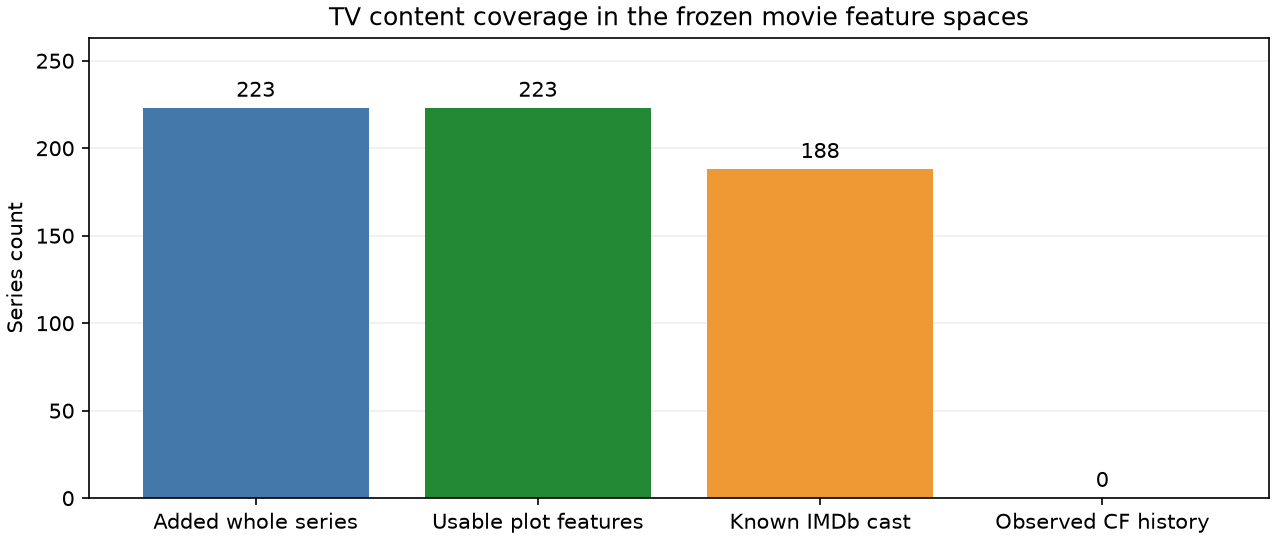

In [7]:
added = coverage.loc[coverage["added"]]
counts = [len(added), int(added["has_plots"].sum()), int(added["has_cast"].sum()), int(added["has_cf"].sum())]
fig, ax = plt.subplots(figsize=(8.5, 3.6), layout="constrained")
bars = ax.bar(["Added whole series", "Usable plot features", "Known IMDb cast", "Observed CF history"],
              counts, color=["#4477AA", "#228833", "#EE9933", "#AA3377"])
ax.bar_label(bars, padding=3)
ax.set(ylabel="Series count", title="TV content coverage in the frozen movie feature spaces")
ax.set_ylim(0, max(counts) * 1.18)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
chart_path = result["output"] / "tv_feature_coverage.png"
fig.savefig(chart_path, dpi=150)
plt.close(fig)
display(Image(filename=str(chart_path)))
manifest = result["manifest"]
manifest["files"][chart_path.name] = {"sha256": file_hash(chart_path)}
_ = (result["output"] / "experiment_manifest.json").write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8")


## Recommendations from real training profiles

Examples are the first three user IDs with an observed training like for a verified whole series, chosen without inspecting validation gains. Their existing training histories drive the recommendations. No new-TV user ratings are fabricated.

The series-only list can include new titles without collaborative history. Its quality requires further labeled feedback; these are actual content-transfer recommendations, not placeholders.


In [8]:
for user in sorted(result["examples"]["userId"].unique()):
    display(Markdown(f"### User {user}"))
    history = result["histories"].loc[result["histories"]["userId"] == user]
    display(history.loc[history["isSeries"], ["title", "rating_out_of_10"]].reset_index(drop=True))
    picks = result["examples"].loc[result["examples"]["userId"] == user]
    display(picks.pivot(index="rank", columns="variant", values="title"))


### User 2

,title,rating_out_of_10
0,The Jinx: The Life and Deaths of Robert Durst (2015),10.0


variant,expanded mixed,original catalog,series only
rank,,,
1,"Departed, The (2006)","Departed, The (2006)","Stand, The (1994)"
2,Catch Me If You Can (2002),Catch Me If You Can (2002),Frozen Planet (2011)
3,"Aviator, The (2004)","Aviator, The (2004)","Decalogue, The (Dekalog) (1989)"
4,Gangs of New York (2002),Gangs of New York (2002),Guest from the Future (Gostya iz buduschego) (1985)
5,"Dark Knight, The (2008)","Dark Knight, The (2008)",Helen of Troy (2003)
6,Kill Bill: Vol. 2 (2004),Kill Bill: Vol. 2 (2004),Lonesome Dove (1989)
7,Fight Club (1999),Fight Club (1999),FLCL (2000)
8,Inglourious Basterds (2009),Inglourious Basterds (2009),Dr. Horrible's Sing-Along Blog (2008)
9,Superbad (2007),Superbad (2007),Planet Earth II (2016)


### User 28

,title,rating_out_of_10
0,Battlestar Galactica (2003),9.0
1,Children of Dune (2003),9.0
2,Dune (2000),10.0
3,"Bourne Identity, The (1988)",8.0
4,Lonesome Dove (1989),8.0
5,Farscape: The Peacekeeper Wars (2004),4.0


variant,expanded mixed,original catalog,series only
rank,,,
1,Indiana Jones and the Last Crusade (1989),Indiana Jones and the Last Crusade (1989),"Stand, The (1994)"
2,Ocean's Eleven (2001),Ocean's Eleven (2001),Battlestar Galactica
3,Unbreakable (2000),Unbreakable (2000),Firefly
4,Sin City (2005),Sin City (2005),Dr. Horrible's Sing-Along Blog (2008)
5,Training Day (2001),Training Day (2001),Helen of Troy (2003)
6,"Truman Show, The (1998)","Truman Show, The (1998)",Frozen Planet (2011)
7,Pirates of the Caribbean: The Curse of the Black Pearl (2003),Pirates of the Caribbean: The Curse of the Black Pearl (2003),"Decalogue, The (Dekalog) (1989)"
8,"Big Lebowski, The (1998)","Big Lebowski, The (1998)",Guest from the Future (Gostya iz buduschego) (1985)
9,"Incredibles, The (2004)","Incredibles, The (2004)",Afro Samurai (2007)


### User 50

,title,rating_out_of_10
0,FLCL (2000),7.0
1,All Watched Over by Machines of Loving Grace (2011),8.0


variant,expanded mixed,original catalog,series only
rank,,,
1,Reservoir Dogs (1992),Reservoir Dogs (1992),"Century of the Self, The (2002)"
2,Apocalypse Now (1979),Apocalypse Now (1979),"Power of Nightmares, The: The Rise of the Politics of Fear (2..."
3,"Godfather, The (1972)","Godfather, The (1972)",Lonesome Dove (1989)
4,2010: The Year We Make Contact (1984),2010: The Year We Make Contact (1984),Scenes From a Marriage (Scener ur ett äktenskap) (1973)
5,One Flew Over the Cuckoo's Nest (1975),One Flew Over the Cuckoo's Nest (1975),Dr. Horrible's Sing-Along Blog (2008)
6,Being John Malkovich (1999),Being John Malkovich (1999),World on a Wire (Welt am Draht) (1973)
7,Goodfellas (1990),Goodfellas (1990),Anne of Green Gables (1985)
8,"Big Lebowski, The (1998)","Big Lebowski, The (1998)","Stand, The (1994)"
9,Alien (1979),Alien (1979),Rose Red (2002)


## Try your own movie and whole-series ratings

Search the catalog below for canonical IDs, then edit `MY_RATINGS_10` with entries shaped as
`{"itemId": "<ID from the catalog>", "rating10": <integer 1–10>}`.
Rate a series as a whole. A rating ≥8 joins your liked profile; **every rated item is excluded**.

The default list is empty so that the notebook does not invent personal ratings. This input affects only local notebook inference and does not update the app or benchmark labels. For later evaluation with actual users, an empty CSV template is saved as `new_user_ratings_template.csv`; do not merge its user IDs with MovieLens users.


In [9]:
SEARCH = "Breaking Bad"
display(items.loc[items["title"].str.contains(SEARCH, case=False, regex=False),
                  ["itemId", "title", "isSeries", "added"]].reset_index(drop=True))

MY_RATINGS_10 = []
if MY_RATINGS_10:
    for kind in ["movies", "series", "mixed"]:
        display(Markdown(f"### Your {kind} recommendations"))
        picks = recommend_profile(model, MY_RATINGS_10, kind=kind)
        display(picks[["rank", "itemId", "title", "isSeries", "score"]])
else:
    print("Add your actual ratings to MY_RATINGS_10, then rerun this cell.")


Add your actual ratings to MY_RATINGS_10, then rerun this cell.


,itemId,title,isSeries,added
0,imdb:tt0903747,Breaking Bad,True,True


## Interpretation and next steps

- The original movie hybrid is preserved and checked numerically. Its few existing series ratings already participate in its profiles.
- New series are usable items with exact identities and real content features. Whole-series ratings can influence both TV and movie recommendations through plot/cast preferences.
- No collaborative TV relationships are inferred from audience averages. New series' CF rows are zero.
- The small observed TV validation subset cannot validate broad TV accuracy. The mixed-catalog diagnostic also penalizes unlabeled new series as missed opportunities for known hits, without proving that those suggestions are bad.
- A useful next measurement would collect actual chronological movie-and-series ratings from the same new users, with a new train/validation/test protocol. Episodes, seasons and full series must remain distinct rating units.
- Current metadata, IMDb aggregates, bounded English-language catalog selection, missing features and uncalibrated cross-domain scores limit generalization.

Re-run top-to-bottom in the existing project kernel. To prepare metadata and run the offline experiment from the repository root:

```powershell
.\.venv\Scripts\python.exe scripts/prepare_tv_series.py
.\.venv\Scripts\python.exe scripts/tv_series_experiment.py
```

Results and source provenance live under
`data/processed/per_user_chronological_60_20_20_v1/notebook15_tv_series/`.
The app model is not changed by this notebook.
